# Offline RL is causal inference: learning a treatment policy from logged data

**Question:** a hospital has years of records of what its doctors did and how patients fared. Can it learn a *better*
treatment policy from those records alone, without experimenting on new patients? And how good would that policy be?

This is offline (batch) reinforcement learning, and it is a causal question in disguise. The value of a policy $\pi$ is
the mean potential outcome of a treatment regime, $V(\pi) = E[Y(\pi)]$; the logs are an observational study collected
under the doctors' behavior policy $\pi_b$. Every tool of the course has an offline-RL name:

| causal inference | offline RL |
|---|---|
| unit, treatment, outcome | episode, action, return |
| potential outcome $Y(t)$ / dynamic treatment regime | policy value $V(\pi)$ |
| observational study | logged dataset from a behavior policy $\pi_b$ |
| propensity score $e(x)$ | behavior policy $\pi_b(a \mid s)$ |
| (sequential) conditional ignorability | no unobserved confounders of action and next state / reward |
| positivity | coverage (concentrability): $\pi_b(a\mid s) > 0$ wherever $\pi$ acts |
| IPW, Hajek | importance sampling, weighted IS |
| g-computation / g-formula | model-based evaluation, fitted Q evaluation (FQE) |
| AIPW / doubly robust | doubly robust OPE (Jiang & Li 2016) |
| CATE-based treatment rule | greedy policy, policy learning |
| positivity violation → extrapolation | distribution shift → overestimated Q-values (pessimism, CQL, BCQ) |
| winner's curse, honesty | optimizer's curse in policy selection |
| unobserved confounding | confounded / partially observable offline RL |

| § | Idea |
|---|---|
| 1 | One decision: offline contextual bandits = CATE-based policy learning on the hospital |
| 2 | Many decisions: the hospital as a 5-visit treatment regime |
| 3 | Off-policy evaluation: IS, PDIS, weighted IS, model-based (g-formula), doubly robust |
| 4 | Positivity becomes coverage: evaluating a policy the doctors almost never followed |
| 5 | Offline policy learning: behavior cloning, fitted Q iteration, pessimism |
| 6 | The optimizer's curse, and honest policy selection |
| 7 | Hidden confounding: what no amount of logged data can fix |

Code: [`src/regime.py`](../src/regime.py) (the multi-visit simulator, exact values by dynamic programming),
[`src/ope.py`](../src/ope.py) (off-policy evaluation), [`src/policy_learning.py`](../src/policy_learning.py), and the
one-step hospital and estimators copied from [12](../../../12-one-dataset-many-estimators/).

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt

from src.hospital import make_hospital
from src import estimators as E
from src import regime as G
from src.ope import ESTIMATORS, estimate_behavior, fit_model
from src.policy_learning import behavior_cloning, fitted_q_iteration, ope_argmax

plt.rcParams["figure.dpi"] = 100

## 1. One decision: offline policy learning on the hospital

With a single decision, offline RL is the **contextual bandit**. A policy $\pi(x) \in \{0, 1\}$ decides who gets
surgery. Its value is

$$V(\pi) = E\big[\pi(X)\,Y(1) + (1 - \pi(X))\,Y(0)\big] = E[Y(0)] + E[\pi(X)\,\tau(X)],$$

so the best policy treats exactly the patients with $\tau(x) > 0$, and learning a policy is learning *the sign of the
CATE*. To evaluate a candidate policy from logs, plug in the doubly robust scores of each arm,
$\Gamma_{i,t} = \hat\mu_t(X_i) + \mathbb{1}[T_i = t]\,\frac{Y_i - \hat\mu_t(X_i)}{\hat P(T = t \mid X_i)}$, and average
$\pi(X_i)\Gamma_{i,1} + (1 - \pi(X_i))\Gamma_{i,0}$: the AIPW estimator of [03](../../../03-propensity-scores/) with one
term per action, and exactly the contextual-bandit value $\beta(x)_a$ of the lecture.

                                            policy | DR estimate | true value
                     the doctors (logged behavior) |       0.607 |      0.605
                               nobody gets surgery |       0.521 |      0.520
                            everybody gets surgery |       0.619 |      0.620
    OLS says surgery helps on average -> everybody |       0.619 |      0.620
       severity threshold learned by DR (c = 0.60) |       0.646 |      0.642


             R-learner: operate iff tau_hat(x) > 0 |       0.645 |      0.641
                    oracle: operate iff tau(x) > 0 |             |      0.642


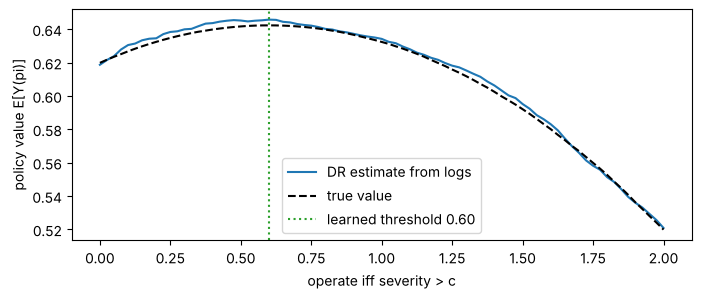

In [2]:
d = make_hospital(4000, seed=0, n_noise=3, nonlinear=True)
X, T, Y = d.X, d.T, d.Y
nu = E.cross_fit_nuisances(X, T, Y)
G1 = nu["mu1"] + T * (Y - nu["mu1"]) / nu["e"]
G0 = nu["mu0"] + (1 - T) * (Y - nu["mu0"]) / (1 - nu["e"])
test = make_hospital(50000, seed=1, n_noise=3, nonlinear=True)

def dr_value(pi_x):                   # off-policy estimate from the logged data
    return float(np.mean(pi_x * G1 + (1 - pi_x) * G0))

def true_value(rule):                 # ground truth on fresh patients
    p = rule(test.X)
    return float(np.mean(test.Y0 + p * test.tau))

# policy class: "operate iff severity > c" (interpretable, like a clinical guideline)
cs = np.linspace(0, 2, 81)
est = [dr_value((d.S > c).astype(float)) for c in cs]
tru = [true_value(lambda x, c=c: (x[:, 0] > c).astype(float)) for c in cs]
c_hat = cs[int(np.argmax(est))]

r = E.r_learner(X, T, Y, nuis=nu)
policies = {
    "nobody gets surgery": lambda x: np.zeros(len(x)),
    "everybody gets surgery": lambda x: np.ones(len(x)),
    "OLS says surgery helps on average -> everybody": lambda x: np.full(len(x), float(E.regression_adjustment(X, T, Y).ate > 0)),
    f"severity threshold learned by DR (c = {c_hat:.2f})": lambda x: (x[:, 0] > c_hat).astype(float),
    "R-learner: operate iff tau_hat(x) > 0": lambda x: (r.cate(x) > 0).astype(float),
    "oracle: operate iff tau(x) > 0": None,
}
print(f"{'policy':>50} | {'DR estimate':>11} | {'true value':>10}")
print(f"{'the doctors (logged behavior)':>50} | {Y.mean():>11.3f} | {np.mean(test.Y):>10.3f}")
for name, rule in policies.items():
    if rule is None:
        print(f"{name:>50} | {'':>11} | {np.mean(test.Y0 + np.maximum(test.tau, 0)):>10.3f}")
        continue
    print(f"{name:>50} | {dr_value(rule(X)):>11.3f} | {true_value(rule):>10.3f}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(cs, est, label="DR estimate from logs"); ax.plot(cs, tru, "k--", label="true value")
ax.axvline(c_hat, color="tab:green", ls=":", label=f"learned threshold {c_hat:.2f}")
ax.set_xlabel("operate iff severity > c"); ax.set_ylabel("policy value E[Y(pi)]"); ax.legend(); plt.show()

The doctors already operate mostly on severe patients, but not consistently. A one-number threshold learned by
maximizing the doubly robust value is close to the oracle, and the CATE-based rule (operate iff $\hat\tau(x) > 0$)
uses age as well. Maximizing a doubly robust value over a policy class with cross-fitted nuisances is the policy
learning method of Athey & Wager (2021), and the orthogonality of the score
([08](../../../08-orthogonal-learning/)) is what keeps nuisance errors from biasing the choice.

## 2. Many decisions: a five-visit treatment regime

Now the patient comes back five times. At each visit the doctor sees the severity $s \in \{0, \dots, 4\}$ and chooses
the drug or surgery; the reward is the patient's health after the visit. Today's choice changes tomorrow's severity,
so actions have delayed effects, and the target is the value of a whole **regime**.

A deterministic policy is a 5-letter string, one letter per severity: `d` drug, `S` surgery. There are 32 of them, and
since the simulator is tabular every policy's true value is computed exactly by dynamic programming.

doctors' policy P(surgery | s) = [0.05 0.18 0.5  0.82 0.95], value 2.931
best policy ddSSS with value 3.113
top 5: ddSSS 3.113, SdSSS 3.049, dSSSS 3.045, SSSSS 2.984, ddSSd 2.892 | worst: SSddd 2.208

logged dataset: 1000 episodes x 5 visits; surgery rate 41%, mean return 2.928


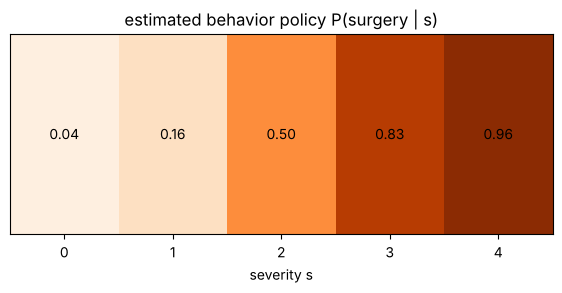

In [3]:
reg = G.Regime()
pi_b = G.behavior_policy()               # doctors: more surgery for severe patients
pi_doc = pi_b[0] * (1 - reg.p_frail) + pi_b[1] * reg.p_frail
pi_star, v_star = G.optimal_policy()
vals = sorted(((G.true_value(p), G.describe(p)) for p in G.all_deterministic_policies()), reverse=True)
print(f"doctors' policy P(surgery | s) = {np.round(pi_doc[:, 1], 2)}, value {G.true_value(pi_doc):.3f}")
print(f"best policy {G.describe(pi_star)} with value {v_star:.3f}")
print("top 5:", ", ".join(f"{n} {v:.3f}" for v, n in vals[:5]), "| worst:", f"{vals[-1][1]} {vals[-1][0]:.3f}")
data = G.simulate(1000, seed=0)
print(f"\nlogged dataset: {data.a.shape[0]} episodes x {data.a.shape[1]} visits; "
      f"surgery rate {data.a.mean():.0%}, mean return {data.r.sum(1).mean():.3f}")
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.imshow(estimate_behavior(data)[:, 1:].T, cmap="Oranges", vmin=0, vmax=1, aspect="auto")
for s in range(G.N_S):
    ax.text(s, 0, f"{estimate_behavior(data)[s, 1]:.2f}", ha="center", va="center")
ax.set_xticks(range(G.N_S)); ax.set_xlabel("severity s"); ax.set_yticks([]); ax.set_title("estimated behavior policy P(surgery | s)")
plt.show()

## 3. Off-policy evaluation

Estimate the value of the best policy `ddSSS` (drug for mild, surgery for severe) from 1000 logged episodes of the
doctors, repeated on 100 independent datasets. Every estimator uses the *estimated* behavior policy, like a fitted
propensity score.

* **IS** reweights each episode's return by $\prod_t \pi(a_t|s_t)/\pi_b(a_t|s_t)$: IPW where the "treatment" is the
  whole action sequence.
* **PDIS** gives reward $r_t$ only the ratios up to $t$: later actions cannot cause earlier rewards (a causal argument
  that cuts variance).
* **Weighted** versions normalize the weights (Hajek).
* **Model-based** fits $\hat P(s'|s,a)$, $\hat R(s,a)$ and evaluates the policy in the fitted model: g-computation,
  the sequential g-formula of Robins (1986). Tabular FQE is the same estimator.
* **Doubly robust** (Jiang & Li 2016) is AIPW, applied recursively backwards in time:
  $V^{t}_{DR} = \hat V_t(s_t) + \rho_t\big(r_t + V^{t+1}_{DR} - \hat Q_t(s_t, a_t)\big)$.

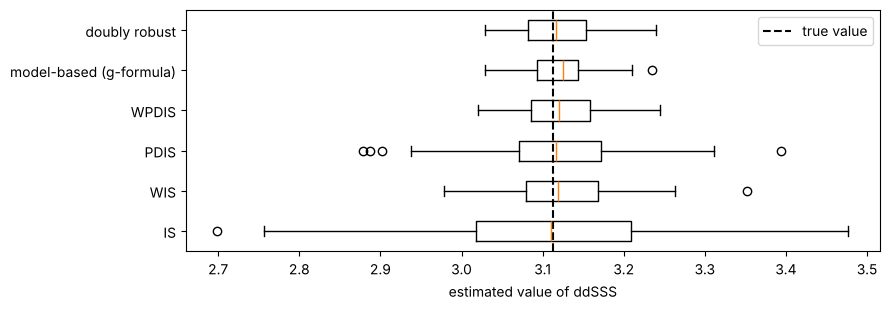

               estimator |    bias     sd   RMSE
                      IS | -0.001 0.145 0.145
                     WIS | +0.007 0.063 0.063
                    PDIS | +0.006 0.089 0.089
                   WPDIS | +0.007 0.050 0.051
 model-based (g-formula) | +0.007 0.040 0.041
           doubly robust | +0.007 0.049 0.050


In [4]:
def run_ope(pi_e, n=1000, reps=100, pi_b=pi_b, seed0=0):
    out = {k: [] for k in ESTIMATORS}
    for r in range(reps):
        dd = G.simulate(n, pi_b=pi_b, seed=seed0 + r)
        for k, f in ESTIMATORS.items():
            out[k].append(f(dd, pi_e))
    return {k: np.array(v) for k, v in out.items()}

res = run_ope(pi_star)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.boxplot(list(res.values()), orientation="horizontal", tick_labels=list(res.keys()))
ax.axvline(v_star, color="k", ls="--", label="true value"); ax.legend(); ax.set_xlabel(f"estimated value of {G.describe(pi_star)}")
plt.tight_layout(); plt.show()
print(f"{'estimator':>24} | {'bias':>7} {'sd':>6} {'RMSE':>6}")
for k, v in res.items():
    print(f"{k:>24} | {v.mean() - v_star:+.3f} {v.std():.3f} {np.sqrt(np.mean((v - v_star) ** 2)):.3f}")

All six are close to unbiased here, because (a) the doctors' choices depend only on the recorded severity (sequential
ignorability) and (b) they sometimes do everything (positivity). They differ in variance: plain IS multiplies five
ratios and is the noisiest; per-decision weighting and normalization help; the model-based estimator uses the Markov
structure and is the most precise; DR sits close to it while staying consistent if the model were wrong.

The variance of IS grows with the horizon, the curse of horizon: the weights are products, and their variance
compounds.

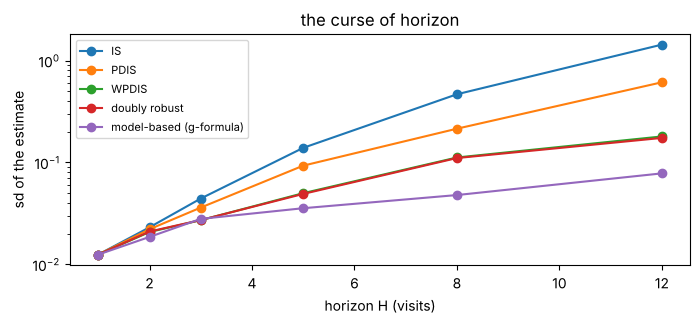

In [5]:
fig, ax = plt.subplots(figsize=(8, 3))
Hs = [1, 2, 3, 5, 8, 12]
sds = {k: [] for k in ["IS", "PDIS", "WPDIS", "doubly robust", "model-based (g-formula)"]}
for H in Hs:
    rg = G.Regime(H=H)
    for k in sds:
        v = [ESTIMATORS[k](G.simulate(1000, regime=rg, seed=500 + r), pi_star) for r in range(40)]
        sds[k].append(np.std(v))
for k, v in sds.items():
    ax.plot(Hs, v, "o-", label=k)
ax.set_yscale("log"); ax.set_xlabel("horizon H (visits)"); ax.set_ylabel("sd of the estimate"); ax.legend(fontsize=8)
ax.set_title("the curse of horizon"); plt.show()

## 4. Positivity becomes coverage

Make the doctors nearly deterministic: almost never operate on mild patients ($P(\text{surgery} \mid s=0) = 0.003$).
Now evaluate "everybody gets surgery" (`SSSSS`). The data contain almost no episodes that follow it.

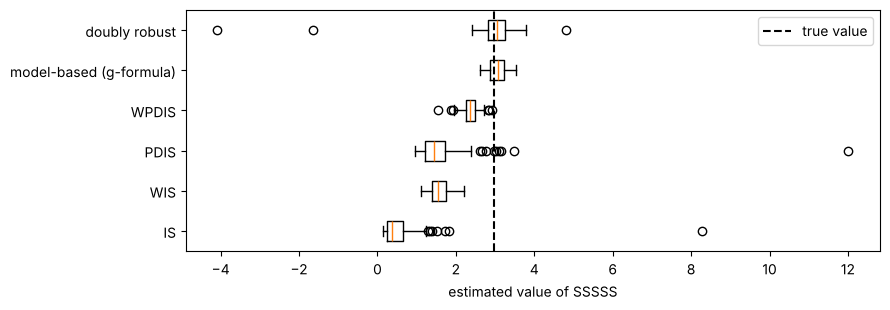

logged visits per (action, severity):
 [[1006 1374  690   12    1]
 [   5   15  677  848  372]]
                      IS | bias -2.400  median error -2.614  sd 0.853
                     WIS | bias -1.398  median error -1.433  sd 0.264
                    PDIS | bias -1.324  median error -1.539  sd 1.163
                   WPDIS | bias -0.605  median error -0.616  sd 0.199
 model-based (g-formula) | bias +0.063  median error +0.090  sd 0.220
           doubly robust | bias -0.031  median error +0.063  sd 0.903


In [6]:
pi_b_strict = G.behavior_policy(slope=4.0, clip=0.003)
allS = G.deterministic_policy([1] * 5)
v_allS = G.true_value(allS)
res2 = run_ope(allS, pi_b=pi_b_strict, reps=100, seed0=1000)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.boxplot(list(res2.values()), orientation="horizontal", tick_labels=list(res2.keys()))
ax.axvline(v_allS, color="k", ls="--", label="true value"); ax.legend(); ax.set_xlabel("estimated value of SSSSS")
plt.tight_layout(); plt.show()
dd = G.simulate(1000, pi_b=pi_b_strict, seed=0)
_, _, N = fit_model(dd)
print("logged visits per (action, severity):\n", N.astype(int))
for k, v in res2.items():
    print(f"{k:>24} | bias {v.mean() - v_allS:+.3f}  median error {np.median(v) - v_allS:+.3f}  sd {v.std():.3f}")

The importance-sampling estimators are still unbiased in theory, but their weights are now $1/0.003 \approx 333$ per
step: almost every dataset contains no matching episode (estimate near zero), and a rare dataset contains one with a
gigantic weight. In 100 repetitions we mostly see the first case, hence the large negative errors. This is a
positivity violation, exactly as in [01](../../../01-potential-outcomes/simpson/). The model-based and DR estimators
fare better because surgery on mild patients is rare but not absent in the data, and the Markov model shares strength
across visits; if the pair were never observed they would have to *extrapolate*, with nothing in the data to check the
guess.

## 5. Offline policy learning

Three ways to pick a policy from logs:

* **Behavior cloning**: copy the doctors. Safe, but never better than them.
* **Fitted Q iteration** (certainty equivalence): optimize in the fitted model. The max over actions is drawn to
  rarely-tried actions whose estimated reward is high by chance: optimism exactly where the data are thinnest.
* **Pessimistic FQI**: subtract $\beta/\sqrt{N(s,a)}$ from the fitted reward (a lower confidence bound). This is the
  principle behind conservative offline RL (CQL, BCQ, LCB methods): only trust what the data support, i.e. respect
  positivity.

Below, with the nearly deterministic doctors of §4, as the dataset grows.

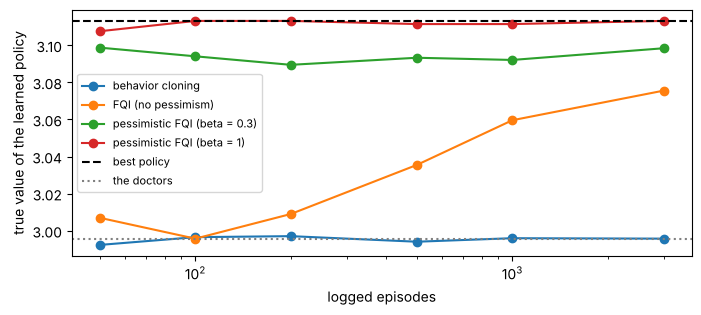

In [7]:
ns = [50, 100, 200, 500, 1000, 3000]
methods = {"behavior cloning": lambda d: behavior_cloning(d),
           "FQI (no pessimism)": lambda d: fitted_q_iteration(d, 0.0),
           "pessimistic FQI (beta = 0.3)": lambda d: fitted_q_iteration(d, 0.3),
           "pessimistic FQI (beta = 1)": lambda d: fitted_q_iteration(d, 1.0)}
perf = {k: [] for k in methods}
for n in ns:
    for k, f in methods.items():
        perf[k].append(np.mean([G.true_value(f(G.simulate(n, pi_b=pi_b_strict, seed=2000 + r))) for r in range(40)]))
fig, ax = plt.subplots(figsize=(8, 3.2))
for k, v in perf.items():
    ax.plot(ns, v, "o-", label=k)
ax.axhline(v_star, color="k", ls="--", label="best policy"); ax.axhline(G.true_value(pi_b_strict[0] * 0.6 + pi_b_strict[1] * 0.4), color="0.5", ls=":", label="the doctors")
ax.set_xscale("log"); ax.set_xlabel("logged episodes"); ax.set_ylabel("true value of the learned policy"); ax.legend(fontsize=8)
plt.show()

## 6. The optimizer's curse, and honest selection

Another route: evaluate all 32 candidate policies with the doubly robust estimator and keep the best. The *reported*
value of the winner is biased upward, because we picked the policy whose estimate happened to be high: the same
winner's curse that makes adaptive causal trees over-confident ([04](../../../04-causal-trees/)). The cure is also the
same: choose on one half of the episodes, report the value estimated on the other half.

In [8]:
rows = {"same data": [], "honest (split)": []}
for r in range(40):
    dd = G.simulate(1000, seed=3000 + r)
    for k, honest in [("same data", False), ("honest (split)", True)]:
        pi, v = ope_argmax(dd, honest=honest, seed=r)
        rows[k].append((v, G.true_value(pi)))
for k, v in rows.items():
    v = np.array(v)
    print(f"{k:>15}: reported value {v[:, 0].mean():.3f}, true value of chosen policy {v[:, 1].mean():.3f}, "
          f"over-statement {np.mean(v[:, 0] - v[:, 1]):+.3f}")
print(f"(best possible {v_star:.3f})")

      same data: reported value 3.260, true value of chosen policy 3.007, over-statement +0.252
 honest (split): reported value 3.028, true value of chosen policy 3.033, over-statement -0.005
(best possible 3.113)


Honest selection loses a little in the quality of the chosen policy (half the data to choose with) but reports a value
you can believe.

## 7. Hidden confounding

So far the doctors decided from the recorded severity alone. Suppose they also see something the records do not:
whether the patient *looks frail* that day. Frail patients recover less from surgery, and doctors avoid operating on
them. Then the patients who were operated on are systematically the robust ones, and every estimator above credits
surgery with recoveries that are really due to robustness: the baseline bias of [01](../../../01-potential-outcomes/),
now at every visit.

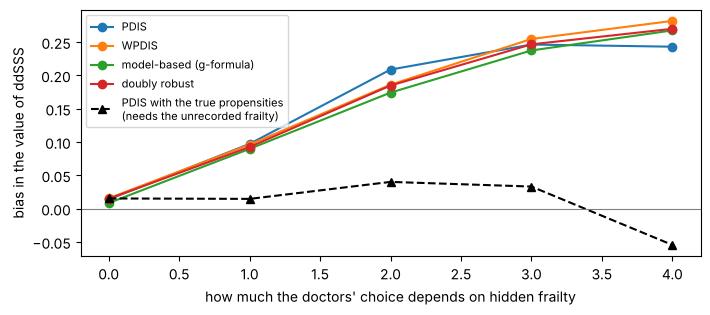

In [9]:
confs = [0.0, 1.0, 2.0, 3.0, 4.0]
bias = {k: [] for k in ["PDIS", "WPDIS", "model-based (g-formula)", "doubly robust"]}
for c in confs:
    res_c = run_ope(pi_star, pi_b=G.behavior_policy(confounding=c), reps=40, seed0=4000)
    for k in bias:
        bias[k].append(res_c[k].mean() - v_star)
known = []
for c in confs:
    v = [ESTIMATORS["PDIS"](dd, pi_star, pb=dd.pb) for dd in (G.simulate(1000, pi_b=G.behavior_policy(confounding=c), seed=4000 + r) for r in range(40))]
    known.append(np.mean(v) - v_star)
fig, ax = plt.subplots(figsize=(8, 3.2))
for k, v in bias.items():
    ax.plot(confs, v, "o-", label=k)
ax.plot(confs, known, "k^--", label="PDIS with the true propensities\n(needs the unrecorded frailty)")
ax.axhline(0, color="0.5", lw=0.8); ax.set_xlabel("how much the doctors' choice depends on hidden frailty")
ax.set_ylabel(f"bias in the value of {G.describe(pi_star)}"); ax.legend(fontsize=8); plt.show()

Every estimator that only sees severity is biased, more data does not help, and none of them can detect the problem
from the logs. Only the propensities that include the hidden variable fix it, and those are exactly what is not
recorded. This is the separation result of the SCM lectures ([06](../../../06-structural-causal-models/)): without an
assumption about the unobserved, the logs do not identify the value of a new policy. The causal toolbox for this case is
the same as in one-shot problems:

* **instruments** and natural experiments (random assignment of patients to doctors with different habits);
* **proxies** of the confounder (bridge functions, the confounded POMDP literature, e.g. Tennenholtz, Mannor & Shalit
  2020);
* **sensitivity analysis and bounds**: report the range of values consistent with a confounder of a given strength
  (e.g. Kallus & Zhou 2020), the RL version of the Austen plots of [07](../../../07-causal-deep-learning/).

## What carries over

* Off-policy evaluation *is* the estimation of a potential outcome under a regime: IS is IPW, the model-based estimate is
  the g-formula, DR is AIPW. The assumptions are the same too: no unobserved confounders and positivity, now at every
  step.
* What is new in the sequential case is the horizon (products of ratios, the curse of horizon), delayed effects (today's
  action changes tomorrow's state, so per-step regression of reward on action is not enough), and the max over actions
  in policy learning, which turns positivity problems into optimism and motivates pessimism.